In [89]:
import datetime as dt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm
from collections import Counter
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
import sklearn.linear_model
from matplotlib import pyplot
from numpy import where
from sklearn import metrics
from sklearn import preprocessing
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
import sklearn.svm
import sklearn.gaussian_process
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import KFold
from sklearn.model_selection import learning_curve
from sklearn.model_selection import train_test_split
from sklearn.model_selection import validation_curve
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

In [90]:
### LIB TO OPEN EXCEL FILE
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path
import joblib

In [91]:
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


## Importing Original Data after removing unwanted columns

In [92]:
root_dir='/content/gdrive/MyDrive/ResearchProject/'
#data_dir = '/content/gdrive/MyDrive/ResearchProject/data/new_data/'
data_dir="/content/gdrive/MyDrive/ResearchProject/data/labeled_normal_data/new_TLSI_input/all_pids_q=0.2.npy"
output_dir = root_dir + "classification_results_2023/"
#original_data= pd.read_csv(data_dir+"/SB-023_original.csv")


In [93]:
data_ndarr = np.load(data_dir, allow_pickle=True)
print("data_ndarr type :", type(data_ndarr))

datadict = data_ndarr.item()
print("datadict type :", type(datadict))

data_ndarr type : <class 'numpy.ndarray'>
datadict type : <class 'dict'>


In [94]:
p_ids = datadict.keys()
smaple_size_dict={}
print("patients: n =", len(p_ids), end='\n\n')

for p_id in p_ids:
    df = datadict[p_id]
    # drop column from input data file
    #df.drop(['id','date','am_pef_org','BMI','sex'], axis=1, inplace=True) #ALL DROPS SHOULD OCCUR HERE
    df.drop(['id','date','am_pef_org','BMI','sex', 'age'], axis=1, inplace=True) #,'id','date','am_pef_org','BMI',  'sex', 'age'
    df = np.asarray(df).astype(np.float32)
    print(p_id, "shape:", df.shape)#, end="\t\t")
    smaple_size_dict[p_id]=df.shape[0]

datadict[p_id].head(4)

patients: n = 26

SB-001 shape: (188, 28)
SB-003 shape: (180, 28)
SB-008 shape: (178, 28)
SB-011 shape: (210, 28)
SB-012 shape: (194, 28)
SB-022 shape: (204, 28)
SB-023 shape: (194, 28)
SB-025 shape: (117, 28)
SB-028 shape: (92, 28)
SB-033 shape: (53, 28)
SB-037 shape: (210, 28)
SB-043 shape: (191, 28)
SB-056 shape: (191, 28)
SB-059 shape: (203, 28)
SB-060 shape: (88, 28)
SB-070 shape: (202, 28)
SB-071 shape: (124, 28)
SB-073 shape: (161, 28)
SB-078 shape: (153, 28)
SB-079 shape: (142, 28)
SB-080 shape: (181, 28)
SB-081 shape: (34, 28)
SB-082 shape: (137, 28)
SB-083 shape: (206, 28)
SB-089 shape: (49, 28)
SB-112 shape: (180, 28)


,income,road_dist,cooking,y_am_pef,tempin,humidin,pm25in,co2in,tempdiffin,humidiffin,...,windsd,humid,varp,dewpt,airp,seap,solrhr,solramnt,grdt,class
1,0.857,0.0,0.167,0.558,0.216,0.513,0.358,0.678,0.562,0.364,...,0.107,0.668,0.174,0.471,0.822,0.819,0.165,0.003,0.206,0.0
2,0.857,0.0,0.167,0.006,0.299,0.521,0.411,0.700,0.436,0.672,...,0.171,0.388,0.190,0.491,0.676,0.670,0.603,0.165,0.383,0.0
3,0.857,0.0,0.167,0.078,0.420,0.713,0.372,0.918,0.469,0.821,...,0.515,0.359,0.197,0.481,0.519,0.518,0.485,0.104,0.346,1.0
4,0.857,0.0,0.167,0.428,0.438,0.468,0.224,0.762,0.560,0.490,...,0.338,0.527,0.175,0.467,0.596,0.596,0.491,0.141,0.339,0.0


In [95]:
target_grp = ["SB-028", "SB-011", "SB-112", "SB-001", "SB-012", "SB-073", "SB-078", "SB-080", "SB-083", "SB-043", "SB-037", "SB-022", "SB-025", "SB-060", "SB-023", "SB-071", "SB-033", "SB-079", "SB-056", "SB-059", "SB-003", "SB-089", "SB-082", "SB-008", "SB-070"]


In [ ]:
print("Patient's data - Columns")
print(original_data.columns)
print("Patient's data- Class counts")
print(original_data['class'].value_counts())

In [ ]:
pefr = original_data['y_am_pef']

## Checking for null values

In [ ]:
original_data.isnull().sum()

In [ ]:

drop_attributes = ['id', 'sex', 'age','am_pef_org','BMI']
original_data = original_data.drop(drop_attributes, axis=1)
original_data .sort_values(by='date', ascending=True, inplace=True)
pefr = original_data ['y_am_pef']
original_data  = original_data.drop(['date'], axis=1) #, 'y_am_pef'
display(original_data .head(5), original_data .tail(5))
original_data.keys()

## Checking Descriptive statistics of the Original data

## Importing Classification function ( classificationv3.py for splitting the data and also executing classification models)

In [96]:
import importlib.util
import os
spec = importlib.util.spec_from_file_location('classification', root_dir + 'classification/Base_Model/Classificationv3.py')
module = importlib.util.module_from_spec(spec)

spec.loader.exec_module(module)

## Setting Classification Models to use

In [97]:
predictColumn = "class"
minorityVariable = 0 # must be an integer

y = original_data[predictColumn]
class_names = y.unique()
class_names[::-1].sort()
n_classes = len(class_names)
if n_classes > 2 :
    logit_reg_model = sklearn.linear_model.LogisticRegression(solver='saga', multi_class='multinomial')
else :
    logit_reg_model = sklearn.linear_model.LogisticRegression(solver='liblinear', multi_class='auto')

cls = [ "DecisionTree" , sklearn.tree.DecisionTreeClassifier(max_depth=4),
        "K-NN"              , sklearn.neighbors.KNeighborsClassifier(),
        "Logit Regression"  , logit_reg_model,
        "Naive Bayes"       , sklearn.gaussian_process.GaussianProcessClassifier()
];

NameError: ignored

In [98]:
predictColumn = "class"
minorityVariable = 0 # must be an integer


## Method for calling classification algo functions for classifying the data and showing the results

In [99]:
#EVALUATION_METRICS = ['Weighted Accuracy', 'Sensitivity/Recall', 'Precision_avg', 'F1_avg', 'Specificity', 'Precision', 'Precision_class1', 'F1', 'F1_class1']
EVALUATION_METRICS = ["Weighted Accuracy", "Sensitivity/Recall", "Specificity", "Precision_class0", "Precision_class1", "Precision_avg", "F1_class0", "F1_class1", "F1_avg", "auc_roc_score", "False_Discovery_Rate", "False_Negative_Rate", "False_Omission_Rate", "False_Positive_Rate", "Jaccard"]


In [100]:
#patient_id="SB-023/"
#file_name="SB-023"
#file_name_synthetic="SB-001_synthetic"

In [101]:
def classification_func(file_name,target, predictCol, minorVar, category_group, cls, output_dir, df_evaluation_results):
    #runtime()

 #   if len(cls)!=2:
  #    print('process one model each time')
   #   return

    print('~~~~~~~~~~~~~~~~~', file_name,'~~~~~~~~~~~~~~~~~~~~~~')
#+ file_name + '/'
    dataset_dir = Path(output_dir +target+'/'+category_group +  "/diagrams/" ) #RESULT_DIR

    # Create Directory for this patient
    if not (dataset_dir.exists() and dataset_dir.is_dir()):
        os.makedirs(dataset_dir)

    print(dataset_dir)

    save_path = output_dir+ target+'/'+category_group +'/diagrams/' + 'sklearn_models_'
    print(save_path)

    CLASS_VAR = predictCol
    MINORITY_VAR = minorVar
## change the data attribute in the Classify method below for eg: original_data or synthetic_data
    dataset = pd.DataFrame()

    dataset=datadict[target].copy()
    bestDT = module.Classify(dataset,target, True, class_var=CLASS_VAR, minority_var=MINORITY_VAR, drawConfusionMatrix=True, classifiers=cls, scale=True, save_path=save_path, after_split=True)

    confusion_matrixes_file = save_path + "confusion_mat_" + category_group + "_"+ file_name
    module.save_confusion_matrix(bestDT[1], confusion_matrixes_file)
    roc_curve_file = save_path + "roc_curve_" + category_group + "_"+ file_name
    module.save_Draw_Roc(bestDT[2], roc_curve_file)
    if len(bestDT[3])!=0:
      featureImportance_path = save_path + "important_mat_" + category_group + "_"+ file_name
      module.save_Draw_FeatureImportanceMatrix(dataset,target,bestDT[3],cls[0], featureImportance_path, True)

    model_path = save_path + "bestModel_" + category_group + "_"+ file_name + ".joblib"
    joblib.dump(bestDT[4], model_path)
    loaded_model = joblib.load(model_path)
    print(loaded_model)

    df_evaluation_results[file_name] = bestDT[0]
    df_evaluation_results.to_csv(output_dir+target+'/'+category_group+"/sklearn_models_balanced_for_train_metrics_"+category_group + ".csv")


In [102]:
%run  '/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py'

<Figure size 640x480 with 0 Axes>

In [103]:
%run  '/content/gdrive/MyDrive/ResearchProject/BalancingAlgorithms/Balance.py'

## Decision Tree Runner

In [104]:
def decisionTreeRunner(category_group):
  for target in tqdm(p_ids):
    if target in ['SB-081','SB-089']:
      continue
    df_evaluation_results = pd.DataFrame(index=EVALUATION_METRICS)
    #category_group = '1DecisionTree'
    file_name=target##creating directory with patient id
    cls = ["DecisionTree", sklearn.tree.DecisionTreeClassifier(max_depth=4)]
    classification_func(file_name,target, predictColumn, minorityVariable, category_group, cls, output_dir, df_evaluation_results)

In [ ]:
decisionTreeRunner('1DecisionTree')

## K-NN

~~~~~~~~~~~~~~~~~ SB-023 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-023/2K-NN/diagrams/SB-023
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-023/2K-NN/diagrams/SB-023/sklearn_models_balanced_for_train_
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  184  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  174  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  130  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  178  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.6743243243243244 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[12 11]
 [14 28]]
cm.ravel() [12 11 14 28]
----- [0.5942029  0.52173913 0.66666667 0.46153846 0.71794872 0.58974359
 0.48979592 0.69135802 0.59057697 0.5942029  

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.6838655462184875 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[12  6]
 [17 30]]
cm.ravel() [12  6 17 30]
----- [0.65248227 0.66666667 0.63829787 0.4137931  0.83333333 0.62356322
 0.5106383  0.72289157 0.61676493 0.65248227 0.33333333 0.16666667
 0.36170213 0.5862069  0.34285714] [[12  6]
 [17 30]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:415: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 8 11]
 [20 25]]
cm.ravel() [ 8 11 20 25]
----- [0.48830409 0.42105263 0.55555556 0.28571429 0.69444444 0.49007937
 0.34042553 0.61728395 0.47885474 0.48830409 0.57894737 0.30555556
 0.44444444 0.71428571 0.20512821] [[ 8 11]
 [20 25]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'distance'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


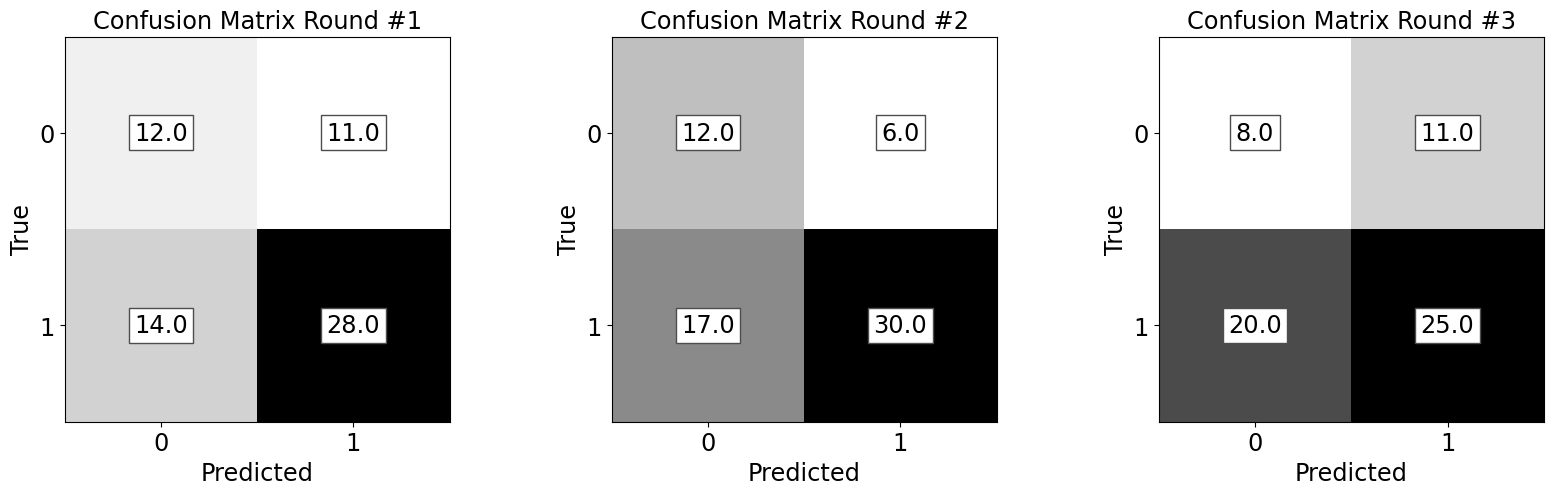

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


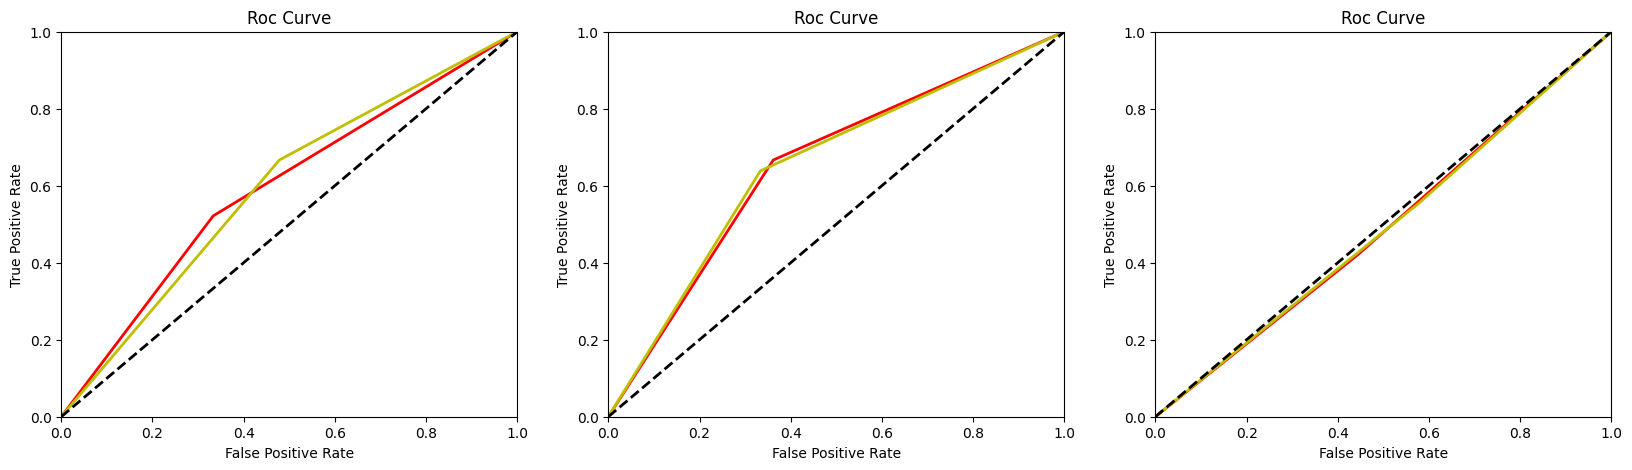

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)


In [ ]:
df_evaluation_results = pd.DataFrame(index=EVALUATION_METRICS)
category_group = '2K-NN'
cls = ["K-NN", sklearn.neighbors.KNeighborsClassifier()]
classification_func(file_name, predictColumn, minorityVariable, category_group, cls, output_dir, df_evaluation_results)

## Logistic Regression

LogisticRegression(solver='liblinear')
~~~~~~~~~~~~~~~~~ SB-023 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-023/LogisticRegression/diagrams/SB-023
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-023/LogisticRegression/diagrams/SB-023/sklearn_models_balanced_for_train_
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  184  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  180  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  130  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  172  ~~~~~~~~~~
~~~~~~~~~~ Logit Regression ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO.

---Logit Regression--- 0.7444444444444445 LogisticRegression(C=1000, penalty='l1', solver='liblinear')


/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


cm [[ 9 14]
 [10 32]]
cm.ravel() [ 9 14 10 32]
----- [0.57660455 0.39130435 0.76190476 0.47368421 0.69565217 0.58466819
 0.42857143 0.72727273 0.57792208 0.57660455 0.60869565 0.30434783
 0.23809524 0.52631579 0.27272727] [[ 9 14]
 [10 32]]
* 0-----------kfold--------------- 1 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

cm [[14  7]
 [16 28]]
cm.ravel() [14  7 16 28]
----- [0.65151515 0.66666667 0.63636364 0.46666667 0.8        0.63333333
 0.54901961 0.70886076 0.62894018 0.65151515 0.33333333 0.2
 0.36363636 0.53333333 0.37837838] [[14  7]
 [16 28]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO.

cm [[12  4]
 [17 31]]
cm.ravel() [12  4 17 31]
----- [0.69791667 0.75       0.64583333 0.4137931  0.88571429 0.64975369
 0.53333333 0.74698795 0.64016064 0.69791667 0.25       0.11428571
 0.35416667 0.5862069  0.36363636] [[12  4]
 [17 31]]
* 2*
{'C': 10, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 100, 'multi_class': 'auto', 'n_jobs': None, 'penalty': 'l2', 'random_state': None, 'solver': 'liblinear', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:415: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


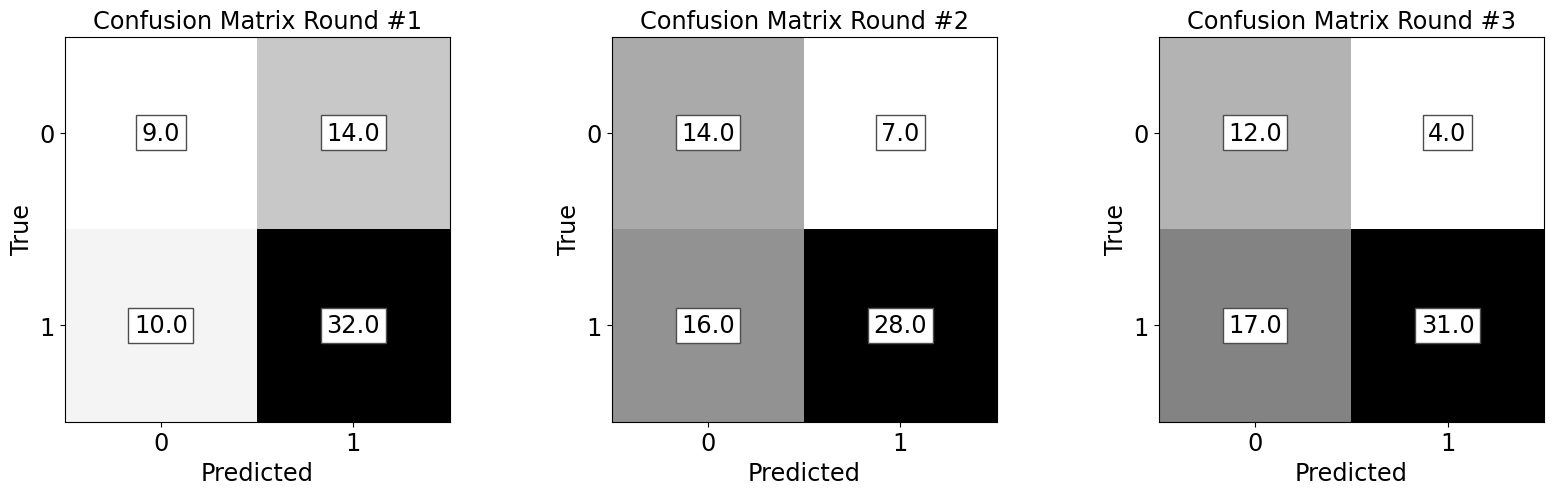

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


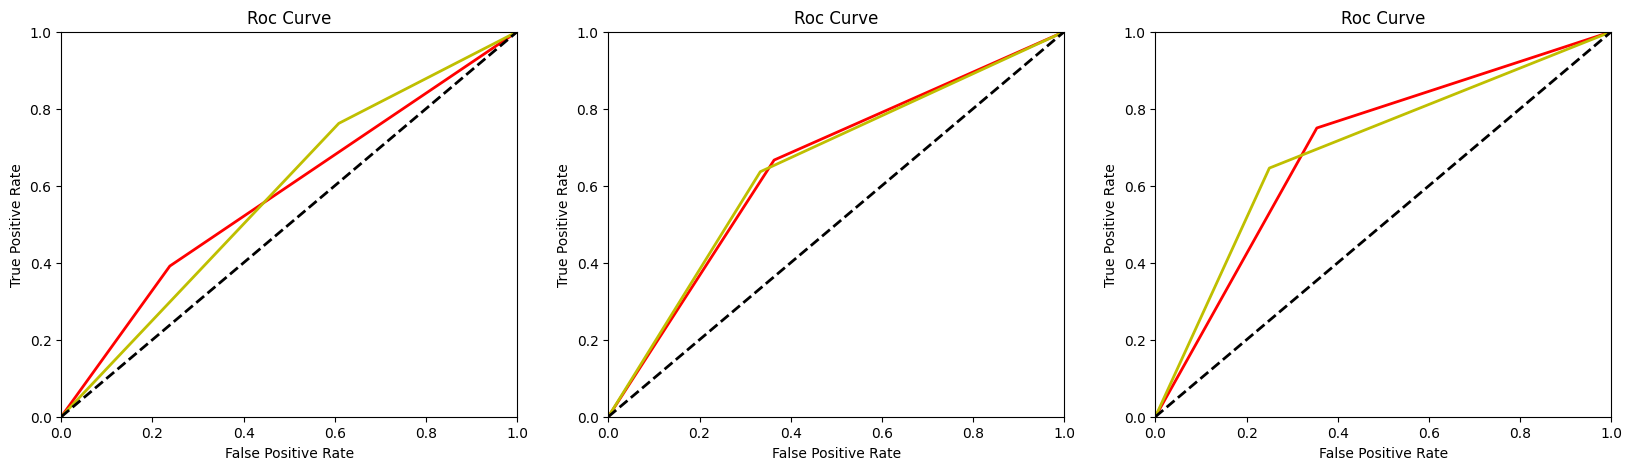

(((((((( draw droc end ))))))))
LogisticRegression(C=1000, penalty='l1', solver='liblinear')


In [ ]:
df_evaluation_results = pd.DataFrame(index=EVALUATION_METRICS)
category_group = 'LogisticRegression'
print(logit_reg_model)
cls = ["Logit Regression", logit_reg_model]
classification_func(file_name, predictColumn, minorityVariable, category_group, cls, output_dir, df_evaluation_results)

## SVM

~~~~~~~~~~~~~~~~~ SB-023 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-023/SVM/diagrams/SB-023
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-023/SVM/diagrams/SB-023/sklearn_models_balanced_for_train_
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  184  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  186  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  130  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  166  ~~~~~~~~~~
~~~~~~~~~~ SVM ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
----SVM kfold---------- 0.722072072072072 SVC(C=11, coef0=1.001, kernel='poly')
cm [[ 7 16]
 [10 32]]
cm.ravel() [ 7 16 10 32]
----- [0.53312629 0.30434783 0.76190476 0.41176471 0.66666667 0.53921569
 0.35       0.71111111 0.53055556 0.53312629 0.69565217 

/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


cm [[17  7]
 [13 28]]
cm.ravel() [17  7 13 28]
----- [0.69563008 0.70833333 0.68292683 0.56666667 0.8        0.68333333
 0.62962963 0.73684211 0.68323587 0.69563008 0.29166667 0.2
 0.31707317 0.43333333 0.45945946] [[17  7]
 [13 28]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:415: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 8  5]
 [16 35]]
cm.ravel() [ 8  5 16 35]
----- [0.65082956 0.61538462 0.68627451 0.33333333 0.875      0.60416667
 0.43243243 0.76923077 0.6008316  0.65082956 0.38461538 0.125
 0.31372549 0.66666667 0.27586207] [[ 8  5]
 [16 35]]
* 2*
{'C': 1, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 2.001, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'poly', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


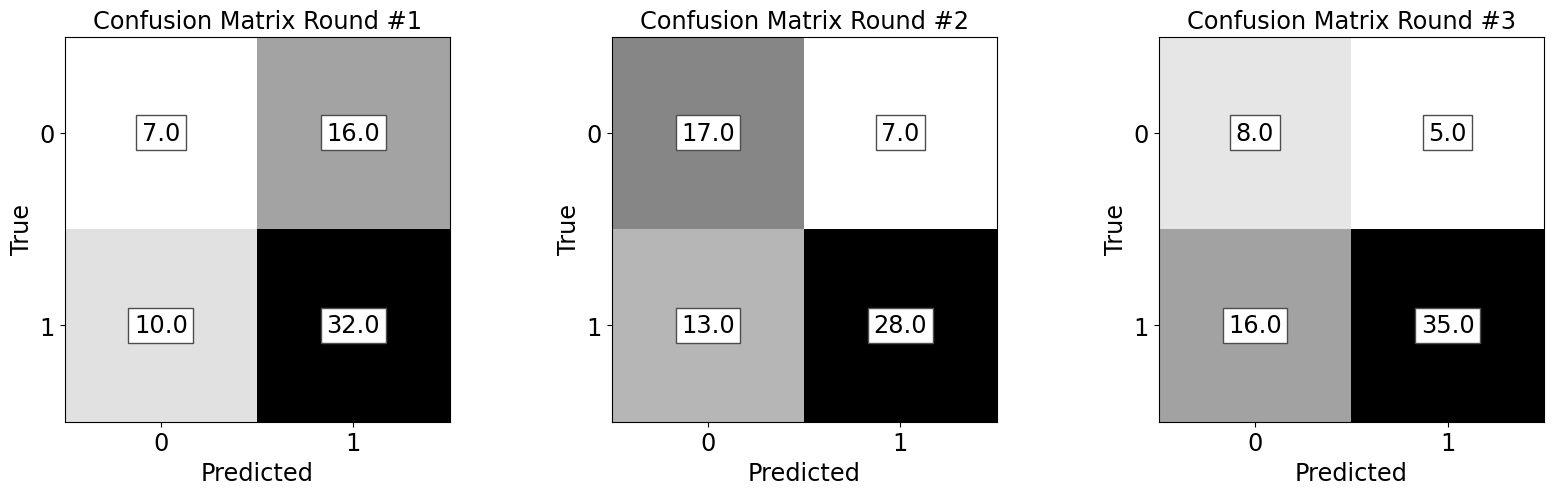

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


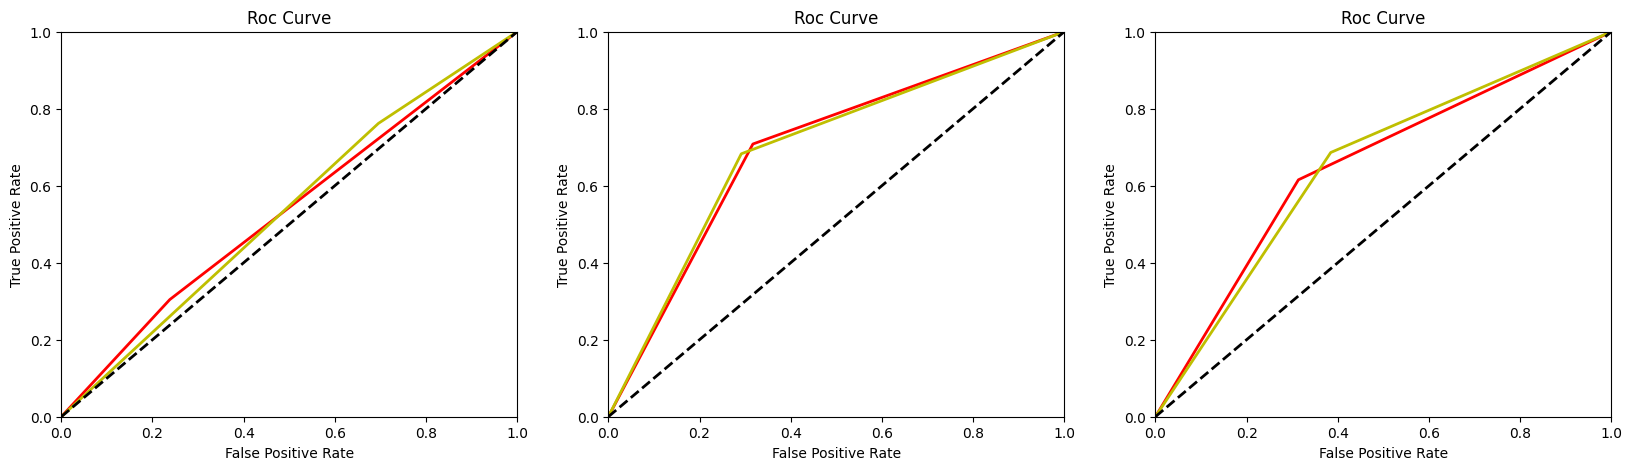

(((((((( draw droc end ))))))))
SVC(C=11, coef0=1.001, kernel='poly')


In [ ]:
df_evaluation_results = pd.DataFrame(index=EVALUATION_METRICS)
category_group = 'SVM'

cls = ["SVM", sklearn.svm.SVC(kernel="linear")]
classification_func(file_name, predictColumn, minorityVariable, category_group, cls, output_dir, df_evaluation_results)

## Naive Bayes

~~~~~~~~~~~~~~~~~ SB-023 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-023/NaiveBayes/diagrams/SB-023
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-023/NaiveBayes/diagrams/SB-023/sklearn_models_balanced_for_train_
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  174  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  172  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  130  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  190  ~~~~~~~~~~
~~~~~~~~~~ Naive Bayes ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning:

---Naive Bayes--- 0.6146218487394958 GaussianProcessClassifier(kernel=1**2 * RBF(length_scale=1), random_state=42)
cm [[10  8]
 [17 30]]
cm.ravel() [10  8 17 30]
----- [0.59692671 0.55555556 0.63829787 0.37037037 0.78947368 0.57992203
 0.44444444 0.70588235 0.5751634  0.59692671 0.44444444 0.21052632
 0.36170213 0.62962963 0.28571429] [[10  8]
 [17 30]]
* 0-----------kfold--------------- 1 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning:

---Naive Bayes--- 0.6388235294117648 GaussianProcessClassifier(kernel=1**2 * RBF(length_scale=1), random_state=42)
cm [[ 7 10]
 [13 35]]
cm.ravel() [ 7 10 13 35]
----- [0.57046569 0.41176471 0.72916667 0.35       0.77777778 0.56388889
 0.37837838 0.75268817 0.56553328 0.57046569 0.58823529 0.22222222
 0.27083333 0.65       0.23333333] [[ 7 10]
 [13 35]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimensio

---Naive Bayes--- 0.7105263157894737 GaussianProcessClassifier(kernel=1**2 * RBF(length_scale=1), random_state=42)


/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


cm [[ 8 17]
 [11 28]]
cm.ravel() [ 8 17 11 28]
----- [0.51897436 0.32       0.71794872 0.42105263 0.62222222 0.52163743
 0.36363636 0.66666667 0.51515152 0.51897436 0.68       0.37777778
 0.28205128 0.57894737 0.22222222] [[ 8 17]
 [11 28]]
* 2*
{'copy_X_train': True, 'kernel__k1': 1**2, 'kernel__k2': RBF(length_scale=1), 'kernel__k1__constant_value': 1.0, 'kernel__k1__constant_value_bounds': (1e-05, 100000.0), 'kernel__k2__length_scale': 1.0, 'kernel__k2__length_scale_bounds': (1e-05, 100000.0), 'kernel': 1**2 * RBF(length_scale=1), 'max_iter_predict': 100, 'multi_class': 'one_vs_rest', 'n_jobs': None, 'n_restarts_optimizer': 0, 'optimizer': 'fmin_l_bfgs_b', 'random_state': 42, 'warm_start': False}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:415: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


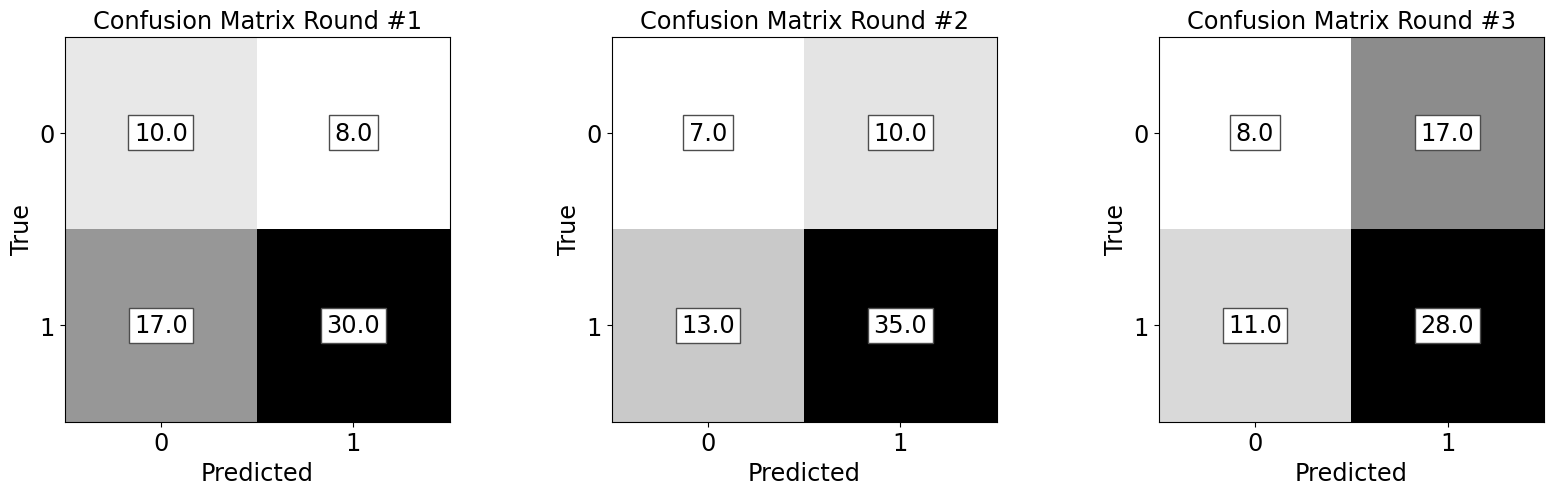

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


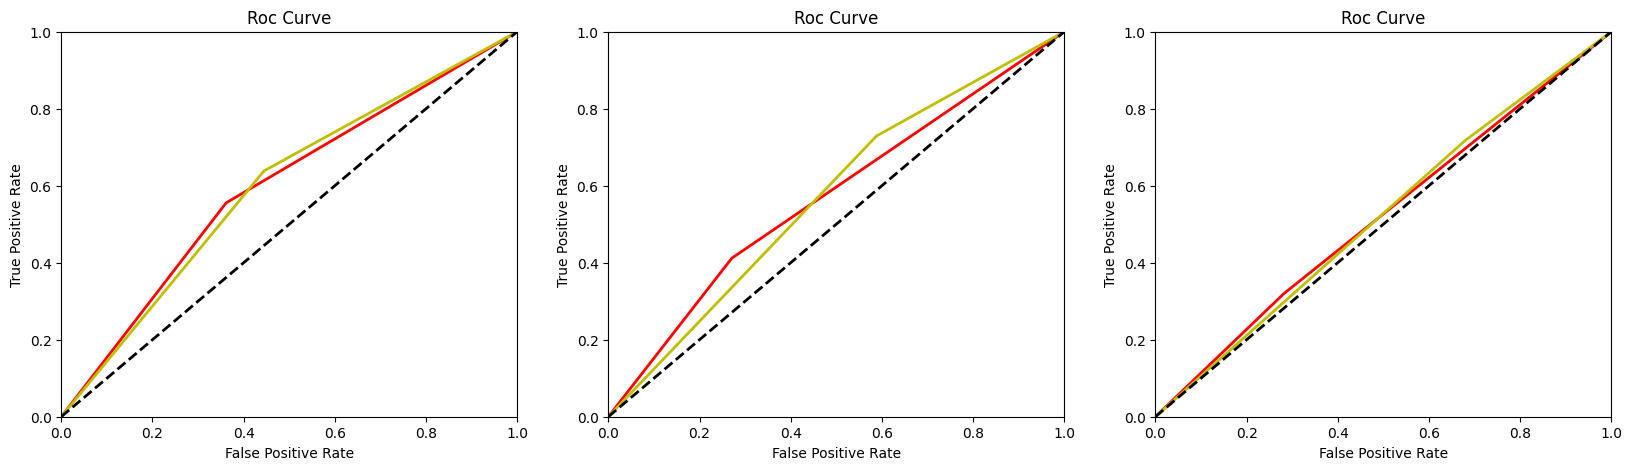

(((((((( draw droc end ))))))))
GaussianProcessClassifier(kernel=1**2 * RBF(length_scale=1), random_state=42)


In [ ]:
df_evaluation_results = pd.DataFrame(index=EVALUATION_METRICS)
category_group = 'NaiveBayes'
cls = ["Naive Bayes", sklearn.gaussian_process.GaussianProcessClassifier()]
classification_func(file_name, predictColumn, minorityVariable, category_group, cls, output_dir, df_evaluation_results)